<a href="https://colab.research.google.com/github/JuanitaRozo/ML-NO-SUPERVISADO/blob/main/ML_NO_SUPERVISADO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
X, y_real = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=1.2,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["Caracteristica_1", "Caracteristica_2"]
)

df.head()

,Caracteristica_1,Caracteristica_2
0,-9.389561,6.303710
1,-9.870824,6.862056
2,-1.522144,7.549274
3,-7.140845,-5.561577
4,-11.284077,6.113819


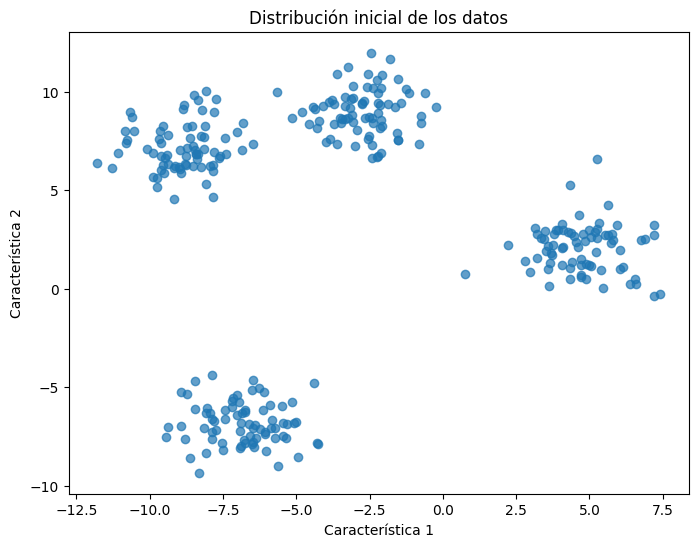

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.7
)

plt.title("Distribución inicial de los datos")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")

plt.show()

In [4]:
inercias = []

for k in range(1, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X)
    inercias.append(modelo.inertia_)

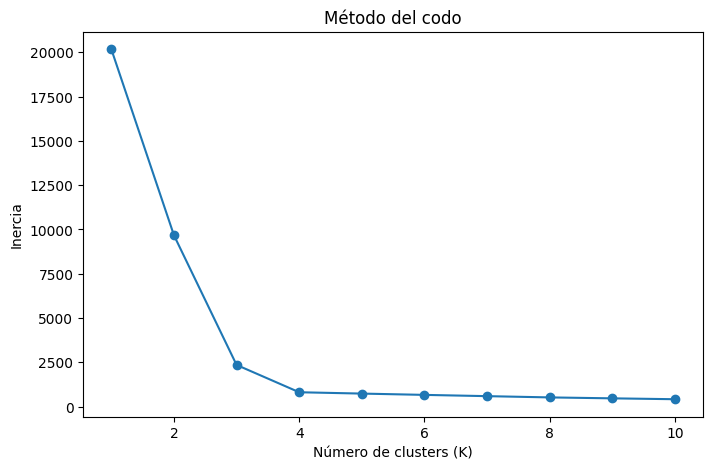

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inercias,
    marker="o"
)

plt.title("Método del codo")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")

plt.show()

In [11]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters_kmeans = kmeans.fit_predict(X)
df["Cluster_KMeans"] = clusters_kmeans

print(df.head())
print("Centroides:")
print(kmeans.cluster_centers_)


   Caracteristica_1  Caracteristica_2  Cluster_KMeans  Cluster_Jerarquico
0         -9.389561          6.303710               3                   3
1         -9.870824          6.862056               3                   3
2         -1.522144          7.549274               0                   0
3         -7.140845         -5.561577               1                   1
4        -11.284077          6.113819               3                   3
Centroides:
[[-2.7332785   8.96731218]
 [-6.82289702 -6.82052706]
 [ 4.73387011  2.05552217]
 [-8.88062107  7.14479553]]


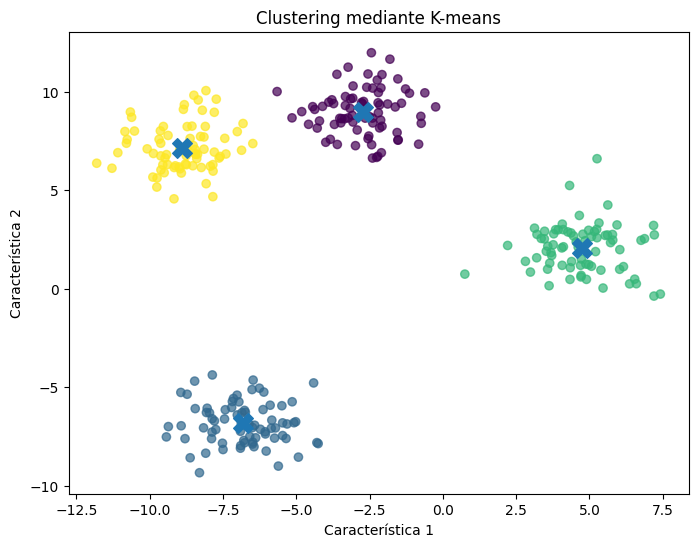

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=clusters_kmeans,
    alpha=0.7
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200
)

plt.title("Clustering mediante K-means")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")

plt.show()

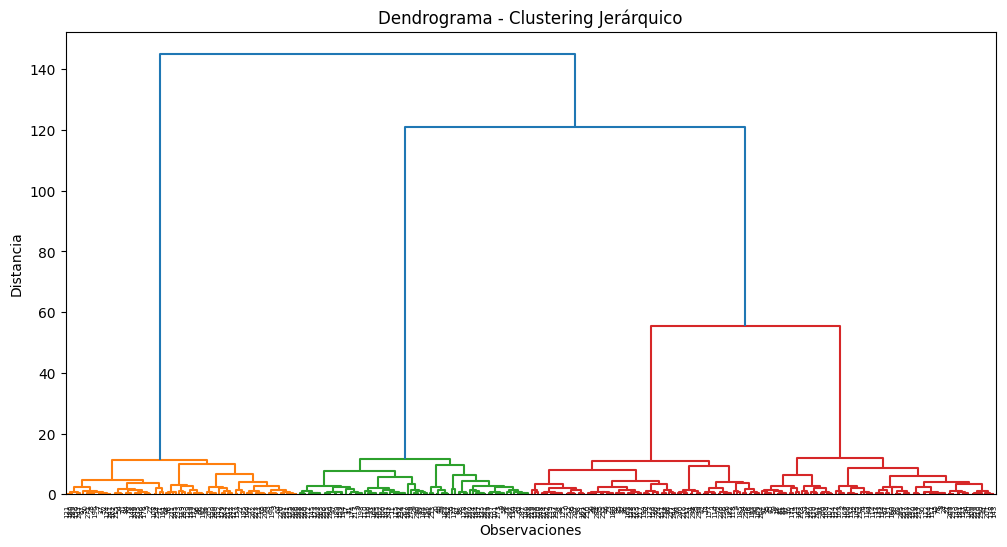

In [8]:
Z = linkage(X, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Dendrograma - Clustering Jerárquico")
plt.xlabel("Observaciones")
plt.ylabel("Distancia")

plt.show()

In [9]:
jerarquico = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

clusters_jerarquico = jerarquico.fit_predict(X)

df["Cluster_Jerarquico"] = clusters_jerarquico

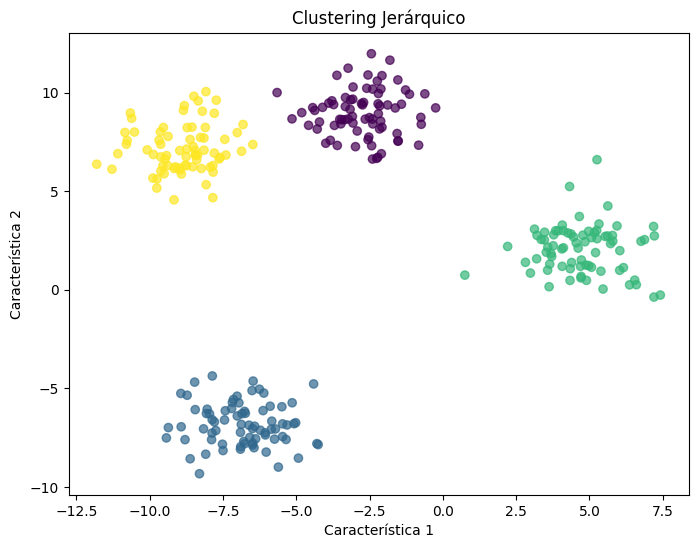

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=clusters_jerarquico,
    alpha=0.7
)

plt.title("Clustering Jerárquico")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")

plt.show()